# Credit card fraud detection

Exact duplicates are removed before stratified 60/20/20 train/validation/test splitting. Training CV reports average precision, recall and F1. A threshold maximizes validation F1; the fitted model is retained. Test threshold tradeoffs are descriptive and do not select the operating threshold. Random splitting does not establish future-period performance.

Saved results are a versioned evaluation snapshot. Set RECOMPUTE=True to retrain.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
ROOT=Path.cwd()
if not (ROOT/'fraud_analysis.py').exists(): ROOT=ROOT.parent
assert (ROOT/'fraud_analysis.py').exists()
sys.path.insert(0,str(ROOT))
RECOMPUTE=False

In [2]:
from fraud_analysis import run
DATA_PATH=ROOT/'data'/'creditcard.csv'
if RECOMPUTE: run(DATA_PATH,ROOT/'results')

{'input_filename': 'creditcard.csv',
 'sha256': '76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89',
 'raw_rows': 284807,
 'duplicate_rows_removed': 1081,
 'rows': 283726,
 'fraud_rows': 473,
 'split_rows': {'train': 170235, 'validation': 56745, 'test': 56746},
 'split_fraud': {'train': 284, 'validation': 94, 'test': 95},
 'validation_threshold': 0.9463769793510437,
 'cv': {'test_ap': 0.8319522821883174,
  'test_recall': 0.8237028742067936,
  'test_f1': 0.8503401979451654},
 'versions': {'numpy': '2.5.4',
  'pandas': '2.3.3',
  'scikit-learn': '1.9.1',
  'xgboost': '3.4.1'}}

,model,operating_point,threshold,average_precision,roc_auc,precision,recall,f1,true_negative,false_positive,false_negative,true_positive
0,XGBoost,default,0.500000,0.817984,0.960891,0.813187,0.778947,0.795699,56634,17,21,74
1,XGBoost,illustrative,0.100000,0.817984,0.960891,0.392157,0.842105,0.535117,56527,124,15,80
2,XGBoost,illustrative,0.250000,0.817984,0.960891,0.629032,0.821053,0.712329,56605,46,17,78
3,XGBoost,illustrative,0.750000,0.817984,0.960891,0.924051,0.768421,0.839080,56645,6,22,73
4,XGBoost,validation F1,0.946377,0.817984,0.960891,0.958904,0.736842,0.833333,56648,3,25,70
5,Logistic regression,default,0.500000,0.686510,0.964562,0.050827,0.873684,0.096065,55101,1550,12,83
6,Prior baseline,default,0.500000,0.001674,0.500000,0.000000,0.000000,0.000000,56651,0,95,0


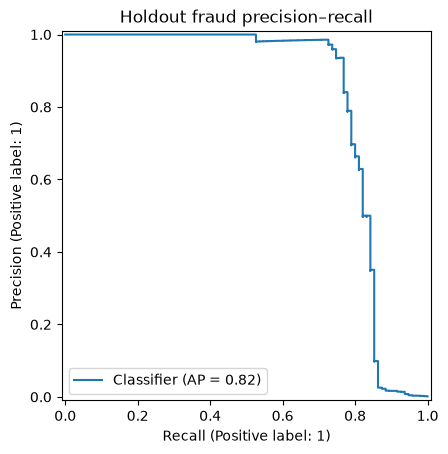

In [3]:
display(json.loads((ROOT/'results'/'summary.json').read_text()))
display(pd.read_csv(ROOT/'results'/'metrics.csv'))
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay
pred=pd.read_csv(ROOT/'results'/'holdout_predictions.csv')
PrecisionRecallDisplay.from_predictions(pred.actual,pred.probability)
plt.title('Holdout fraud precision–recall')
plt.show()